In [27]:
import geopandas as gpd
import pandas as pd
from matplotlib import pyplot as plt


In [38]:
gdf_located_places = gpd.read_file("N-T-located-places-v3.geojson")
gdf_located_places.sample(50)

,place_name,type,local_type,postcode_district,populated_place,county_unitary,approx_match_flag,adjusted_name,found_where,geometry
656,West Bergholt,populatedPlace,Village,CO6,None,Essex,False,West Bergholt,OS,POINT (596282 227660)
172,Basildon Council Local Plan,populatedPlace,Town,SS14,None,Essex,True,Basildon,OS,POINT (570054 188605)
415,Aslacton,populatedPlace,Village,NR15,None,Norfolk,False,Aslacton,OS,POINT (615675 291092)
299,Flatford Mill,None,None,None,None,None,False,Flatford Mill,OSM,POINT (607711.235 233239.723)
37,Hoxne,populatedPlace,Village,IP21,None,Suffolk,False,Hoxne,OS,POINT (617945 277017)
883,Offton,populatedPlace,Village,IP8,None,Suffolk,False,Offton,OS,POINT (607260 249374)
120,Babergh,None,None,None,None,None,False,Babergh,OSM,POINT (600009.94 243142.09)
757,Chelmer Valley,None,None,None,None,None,True,Chelmer,OSM,POINT (573519.921 207517.954)
501,Rivenhall Incinerator,populatedPlace,Village,CM8,None,Essex,True,Rivenhall,OS,POINT (582883 217522)
72,Lion Road,transportNetwork,Section Of Named Road,IP22,Palgrave,Suffolk,False,Lion Road,OS,POINT (611374 278396)


In [39]:
gdf_located_places.loc[gdf_located_places["place_name"] == "Dedham Vale"]

,place_name,type,local_type,postcode_district,populated_place,county_unitary,approx_match_flag,adjusted_name,found_where,geometry
451,Dedham Vale,None,None,None,None,None,False,Dedham Vale,OSM,POINT (607732.997 232684.595)


<Axes: >

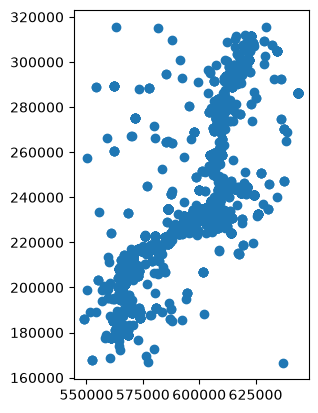

In [5]:
gdf_representations = pd.read_csv("gdf_representations.csv", index_col = 0)
gdf_representations["all_located_points"] = gpd.GeoSeries.from_wkt(gdf_representations["all_located_points"])
gdf_representations["geometry"] = gpd.GeoSeries.from_wkt(gdf_representations["geometry"])
gdf_representations["centroid"] = gpd.GeoSeries.from_wkt(gdf_representations["centroid"])
gdf_representations["spider"] = gpd.GeoSeries.from_wkt(gdf_representations["spider"])
gdf_representations["bounding_box"] = gpd.GeoSeries.from_wkt(gdf_representations["bounding_box"])
gdf_representations = gpd.GeoDataFrame(gdf_representations, geometry = "all_located_points")
gdf_representations.plot()

<Axes: >

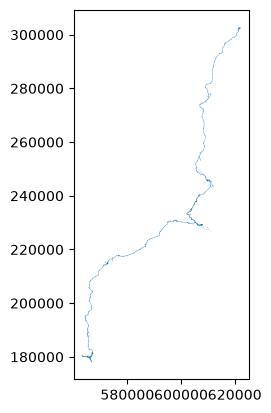

In [13]:
gdf_route = gpd.read_file("../Routes/norwich-tilbury-boundary.geojson")
gdf_route = gdf_route.iloc[[2]].to_crs("epsg:27700")
gdf_route.plot()

In [17]:
gdf_buffer = gdf_route.buffer(20000)
buffer = gdf_buffer[2]


In [18]:
gdf_OAs = gpd.read_file(r"D:\Profiles\Tim\Documents\Community Response\community-response-preprocessing\data\raw\community-response-source\OAs\output_areas.gpkg",
                        mask = buffer)

<Axes: >

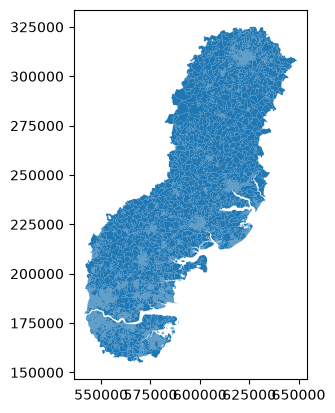

In [19]:
gdf_OAs.plot()

In [22]:
# There are 12806 of the bastards.
# Using an aggregation may be essential.

In [33]:
n = 0
def count_representations(geom):
    global n
    df = gdf_representations.loc[gdf_representations["geometry"].intersects(geom)]
    n += 1
    print(n, end = ",")
    return df.shape[0]
gdf_OAs["num_representations"] = gdf_OAs["geometry"].map(lambda geom:count_representations(geom))

1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,

<Axes: >

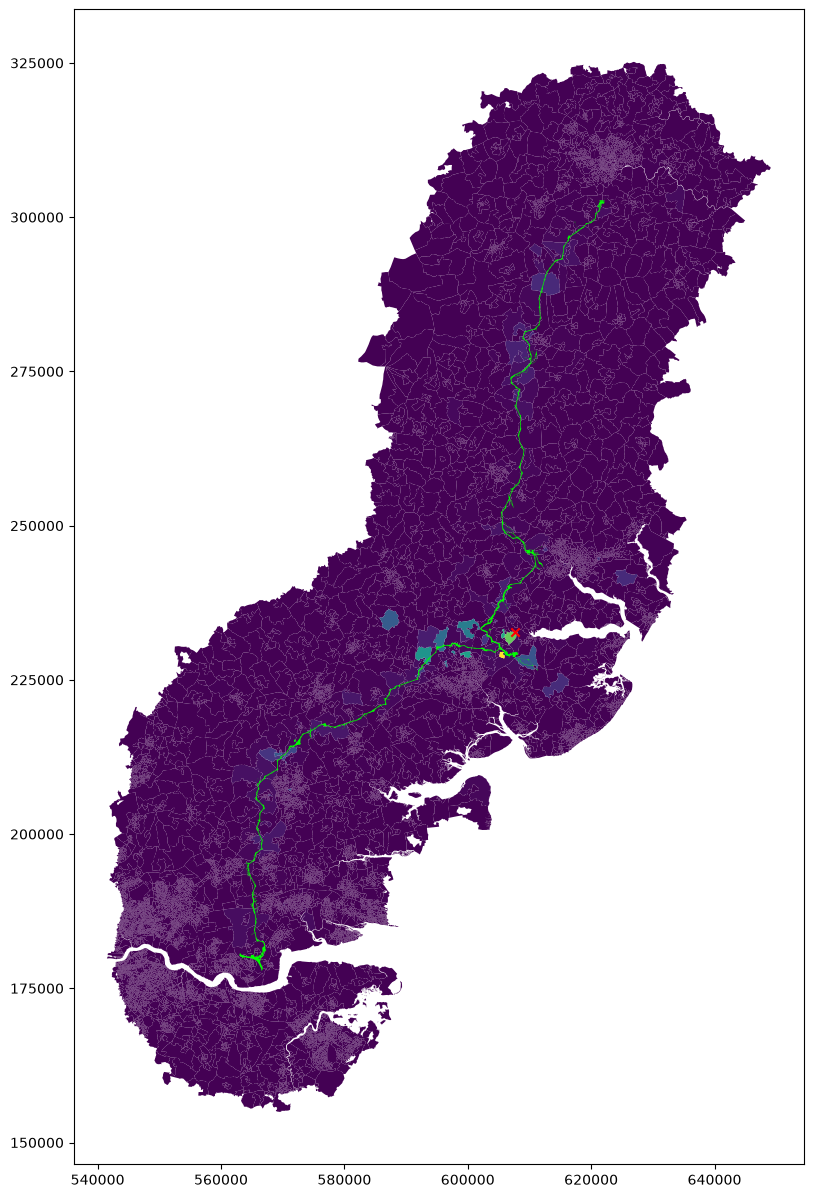

In [42]:
fig, ax = plt.subplots(figsize = (15,15))
gdf_OAs.plot(ax = ax,column = "num_representations")
gdf_located_places.loc[gdf_located_places["place_name"] == "Dedham Vale"].plot(marker = 'x', color = 'red', ax = ax)
gdf_route.plot(ax = ax, color = "lime")

In [36]:
gdf_LSOA = gdf_OAs.loc[:,["geometry", "num_representations", "aggregation_small"]].dissolve("aggregation_small", aggfunc = "sum")

<Axes: >

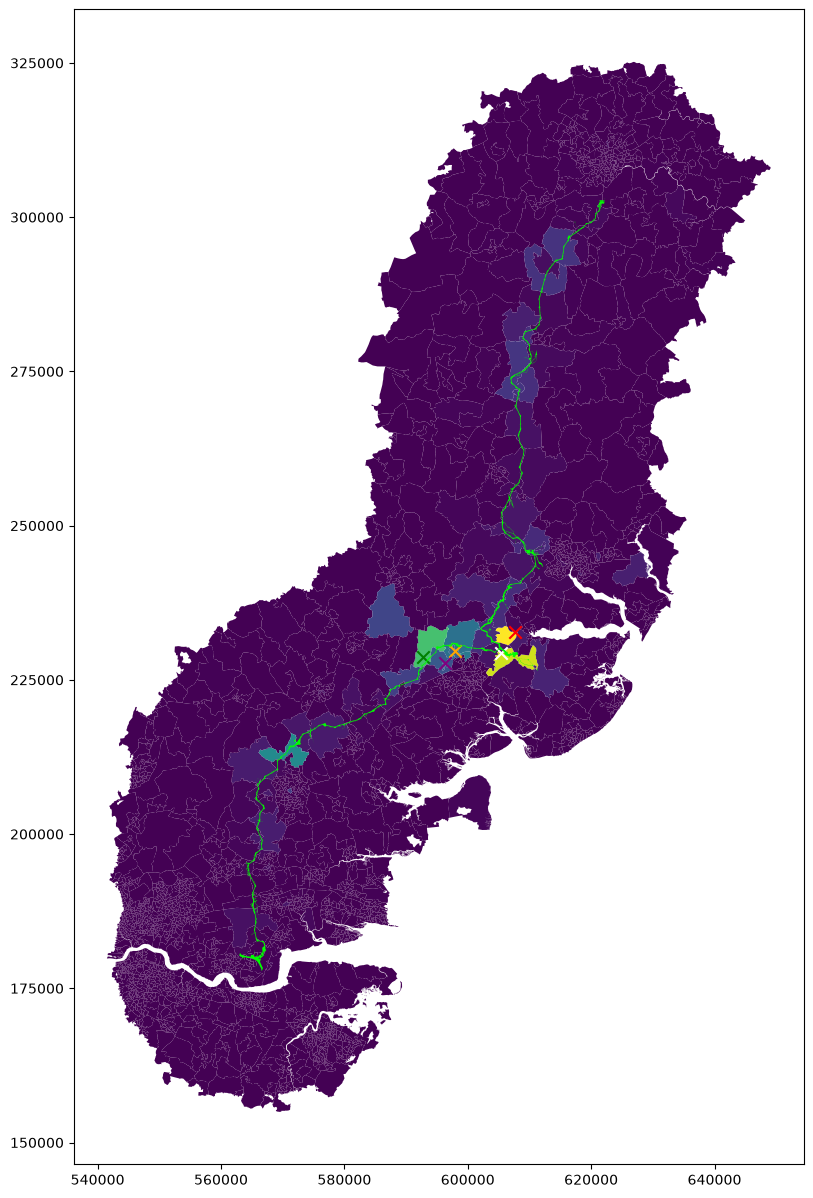

In [45]:
fig, ax = plt.subplots(figsize = (15,15))
gdf_LSOA.plot(ax = ax,column = "num_representations")
msize = 80
gdf_located_places.loc[gdf_located_places["place_name"] == "Dedham Vale"].plot(marker = 'x', color = 'red', ax = ax, markersize = msize)
gdf_located_places.loc[gdf_located_places["place_name"] == "Ardleigh"].plot(marker = 'x', color = 'white', ax = ax, markersize = msize)
gdf_located_places.loc[gdf_located_places["place_name"] == "Fordham"].plot(marker = 'x', color = 'green', ax = ax, markersize = msize)
gdf_located_places.loc[gdf_located_places["place_name"] == "Great Horkesley"].plot(marker = 'x', color = 'orange', ax = ax, markersize = msize)
gdf_located_places.loc[gdf_located_places["place_name"] == "West Bergholt"].plot(marker = 'x', color = 'purple', ax = ax, markersize = msize)
gdf_route.plot(ax = ax, color = "lime")